In [2]:
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from collections import deque
from copy import deepcopy
# For cleaner notebook output
%matplotlib inline
plt.rcParams['figure.figsize'] = (10, 7)
plt.rcParams['figure.dpi'] = 100

In [3]:
# Build the maze graph
maze = nx.Graph()
# Add all edges (undirected — each edge goes both ways)
maze_edges = [
 ('S', '1'), ('S', '6'), ('S', '8'),('1', '2'), ('1', '3'), ('6', '5'), ('6', '7'), ('8', '7'),('8', '14'),
 ('2', '10'),('2', '11'), ('3', '12'),('3', '4'),('4', '13'),('4', '5'),('5', '9'),('9', '7'),('9', 'T')
 
]
maze.add_edges_from(maze_edges)
print(f"Nodes ({maze.number_of_nodes()}): {sorted(maze.nodes())}")
print(f"Edges ({maze.number_of_edges()}): {list(maze.edges())}")
print(f"\nDead-end nodes (degree 1): {[n for n in maze.nodes() if maze.degree(n) == 1]}")
print(f"Cycles present: {len(nx.cycle_basis(maze)) > 0}")

Nodes (16): ['1', '10', '11', '12', '13', '14', '2', '3', '4', '5', '6', '7', '8', '9', 'S', 'T']
Edges (18): [('S', '1'), ('S', '6'), ('S', '8'), ('1', '2'), ('1', '3'), ('6', '5'), ('6', '7'), ('8', '7'), ('8', '14'), ('2', '10'), ('2', '11'), ('3', '12'), ('3', '4'), ('5', '4'), ('5', '9'), ('7', '9'), ('4', '13'), ('9', 'T')]

Dead-end nodes (degree 1): ['14', '10', '11', '12', '13', 'T']
Cycles present: True


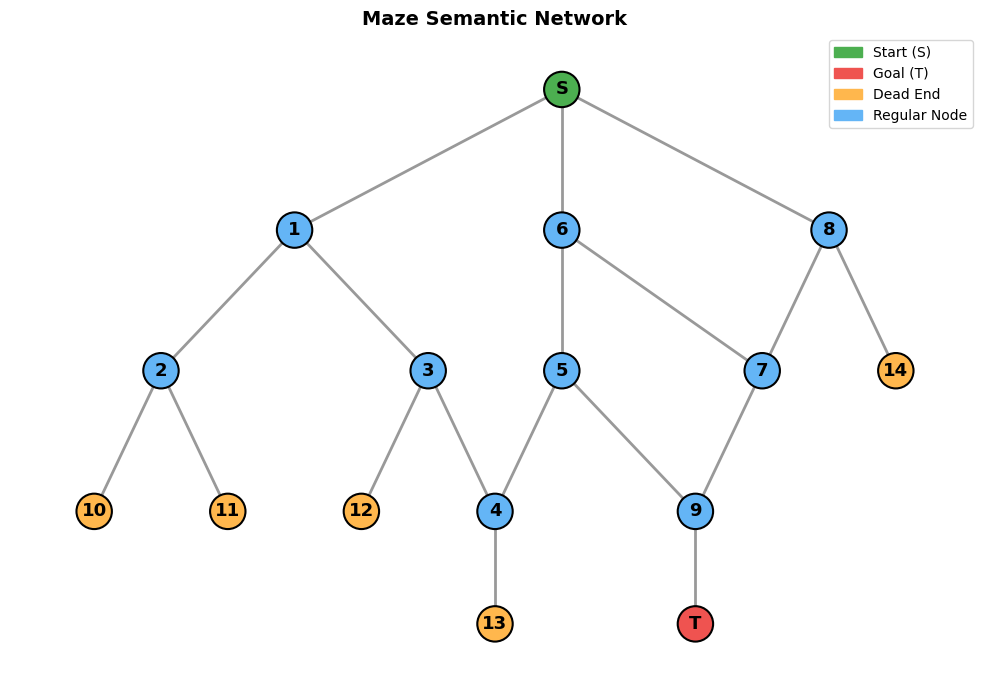

In [4]:
# Fixed positions for consistent layout
maze_pos = {
    'S': (0, 3),
    '1': (-2, 2), '6': (0, 2), '8': (2, 2),
    '2': (-3, 1), '3': (-1, 1), '5': (0, 1), '7': (1.5, 1),
    '10': (-3.5, 0), '11': (-2.5, 0), '12': (-1.5, 0), '4': (-0.5, 0),
    '14': (2.5, 1),
    '13': (-0.5, -0.8),
    '9': (1, 0),
    'T': (1, -0.8)
}

def get_node_colors(graph, start='S', goal='T'):
    """Return a list of colours for each node based on its role."""
    colors = []
    for n in graph.nodes():
        if n == start:
            colors.append('#4CAF50') # Green — start
        elif n == goal:
            colors.append('#EF5350') # Red — goal
        elif graph.degree(n) == 1:
            colors.append('#FFB74D') # Orange — dead end
        else:
            colors.append('#64B5F6') # Blue — regular
    return colors

def draw_maze(graph, pos, title='Maze Semantic Network',
            highlight_edges=None, highlight_nodes=None):
    """Draw the maze graph with optional highlighted path."""
    fig, ax = plt.subplots(figsize=(10, 7))

    node_colors = get_node_colors(graph)

    # Draw base graph
    nx.draw(graph, pos, ax=ax, with_labels=True,
        node_color=node_colors, node_size=650,
        font_size=13, font_weight='bold',
        edge_color='#999999', width=2,
        edgecolors='black', linewidths=1.5)

    # Highlight path if provided
    if highlight_edges:
        nx.draw_networkx_edges(graph, pos, edgelist=highlight_edges,
                                edge_color='#E91E63', width=4, ax=ax)
    if highlight_nodes:
        nx.draw_networkx_nodes(graph, pos, nodelist=highlight_nodes,
                                node_color='#E91E63', node_size=650,
                                edgecolors='black', linewidths=1.5, ax=ax)
        nx.draw_networkx_labels(graph, pos,
                                labels={n: n for n in highlight_nodes},
                                font_size=13, font_weight='bold', ax=ax)

    # Legend
    legend_elements = [
        mpatches.Patch(color='#4CAF50', label='Start (S)'),
        mpatches.Patch(color='#EF5350', label='Goal (T)'),
        mpatches.Patch(color='#FFB74D', label='Dead End'),
        mpatches.Patch(color='#64B5F6', label='Regular Node'),
    ]
    if highlight_edges:
        legend_elements.append(mpatches.Patch(color='#E91E63', label='Found Path'))
    ax.legend(handles=legend_elements, loc='upper right', fontsize=10)

    ax.set_title(title, fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

# Draw the maze
draw_maze(maze, maze_pos)

In [5]:
# Basic graph properties
print("Graph Properties")
print("=" * 40)
# TODO: code to print the number of nodes
print(f"Number of nodes: {nx.number_of_nodes(maze)}")
# TODO: code to print the number of edges
print(f"Number of nodes: {nx.number_of_edges(maze)}")
print(f"Average degree: {sum(dict(maze.degree()).values()) / maze.number_of_nodes():.2f}")
print(f"Number of cycles: {len(nx.cycle_basis(maze))}")
print(f"\nAdjacency list:")
for node in sorted(maze.nodes()):
 neighbors = sorted(maze.neighbors(node))
 print(f" {node:>2} -> {neighbors}")

Graph Properties
Number of nodes: 16
Number of nodes: 18
Average degree: 2.25
Number of cycles: 3

Adjacency list:
  1 -> ['2', '3', 'S']
 10 -> ['2']
 11 -> ['2']
 12 -> ['3']
 13 -> ['4']
 14 -> ['8']
  2 -> ['1', '10', '11']
  3 -> ['1', '12', '4']
  4 -> ['13', '3', '5']
  5 -> ['4', '6', '9']
  6 -> ['5', '7', 'S']
  7 -> ['6', '8', '9']
  8 -> ['14', '7', 'S']
  9 -> ['5', '7', 'T']
  S -> ['1', '6', '8']
  T -> ['9']


In [6]:
def bfs(graph, start, goal):
    """
    Breadth-First Search on a NetworkX graph.

    Parameters:
    graph: A NetworkX graph
    start: The starting node
    goal: The goal node

    Returns:
    traversal_order: List of nodes in the order they were visited
    path: List of nodes forming the path from start to goal
    (None if no path exists)
    queue_states: List of queue snapshots at each step (for tracing)
    """
    visited = set()
    # Each queue entry is (node, path_to_node)
    queue = deque([(start, [start])])
    traversal_order = []
    queue_states = []

    while queue:
        # Record the current state of the queue (for tracing)
        queue_states.append([node for node, _ in queue])

        # Dequeue from the FRONT (FIFO)
        # TODO: use the proper function to deque and get 'node' and 'path' from 'queue'

        node, path = queue.popleft()

        if node in visited:
            continue

        # TODO: add 'node' to 'visited'
        visited.add(node)
        traversal_order.append(node)

        # Goal test
        if node == goal:
            return traversal_order, path, queue_states

        # Enqueue unvisited neighbours at the BACK
        for neighbor in sorted(graph.neighbors(node)):
            if neighbor not in visited:
                queue.append((neighbor, path + [neighbor]))

    return traversal_order, None, queue_states

In [7]:
bfs_order, bfs_path, bfs_queues = bfs(maze, 'S', 'T')
print("BFS Traversal Order:", bfs_order)
print(f"\nPath found: {' -> '.join(bfs_path)}")
print(f"Path length: {len(bfs_path) - 1} edges")

BFS Traversal Order: ['S', '1', '6', '8', '2', '3', '5', '7', '14', '10', '11', '12', '4', '9', '13', 'T']

Path found: S -> 6 -> 5 -> 9 -> T
Path length: 4 edges


In [8]:
def trace_bfs(graph, start, goal):
    """Run BFS and print a detailed trace of the queue at each step."""
    visited = set()
    # TODO: create the queue here (see Cell 2.2)
    queue = deque([(start, [start])])

    step = 0

    print(f"{'Step':>4} {'Visiting':>10} {'Queue (after expanding)':}")
    print("-" * 70)

    while queue:
        # TODO: Dequeue node and path from the FRONT (see Cell 2.2)
        node, path = queue.popleft()

        if node in visited:
            continue

         # TODO: add 'node' to 'visited' 
        visited.add(node)

        step += 1

        if node == goal:
            print(f"{step:>4} {node:>10} ** GOAL FOUND **")
            print(f"\nPath: {' -> '.join(path)}")
            print(f"Path length: {len(path) - 1} edges")
            return path

    # Add unvisited neighbours
        for neighbor in sorted(graph.neighbors(node)):
            if neighbor not in visited:
                queue.append((neighbor, path + [neighbor]))

        queue_contents = [n for n, _ in queue]
        print(f"{step:>4} {node:>10} {queue_contents}")

    return None
bfs_result = trace_bfs(maze, 'S', 'T')

Step   Visiting Queue (after expanding)
----------------------------------------------------------------------
   1          S ['1', '6', '8']
   2          1 ['6', '8', '2', '3']
   3          6 ['8', '2', '3', '5', '7']
   4          8 ['2', '3', '5', '7', '14', '7']
   5          2 ['3', '5', '7', '14', '7', '10', '11']
   6          3 ['5', '7', '14', '7', '10', '11', '12', '4']
   7          5 ['7', '14', '7', '10', '11', '12', '4', '4', '9']
   8          7 ['14', '7', '10', '11', '12', '4', '4', '9', '9']
   9         14 ['7', '10', '11', '12', '4', '4', '9', '9']
  10         10 ['11', '12', '4', '4', '9', '9']
  11         11 ['12', '4', '4', '9', '9']
  12         12 ['4', '4', '9', '9']
  13          4 ['4', '9', '9', '13']
  14          9 ['9', '13', 'T']
  15         13 ['T']
  16          T ** GOAL FOUND **

Path: S -> 6 -> 5 -> 9 -> T
Path length: 4 edges


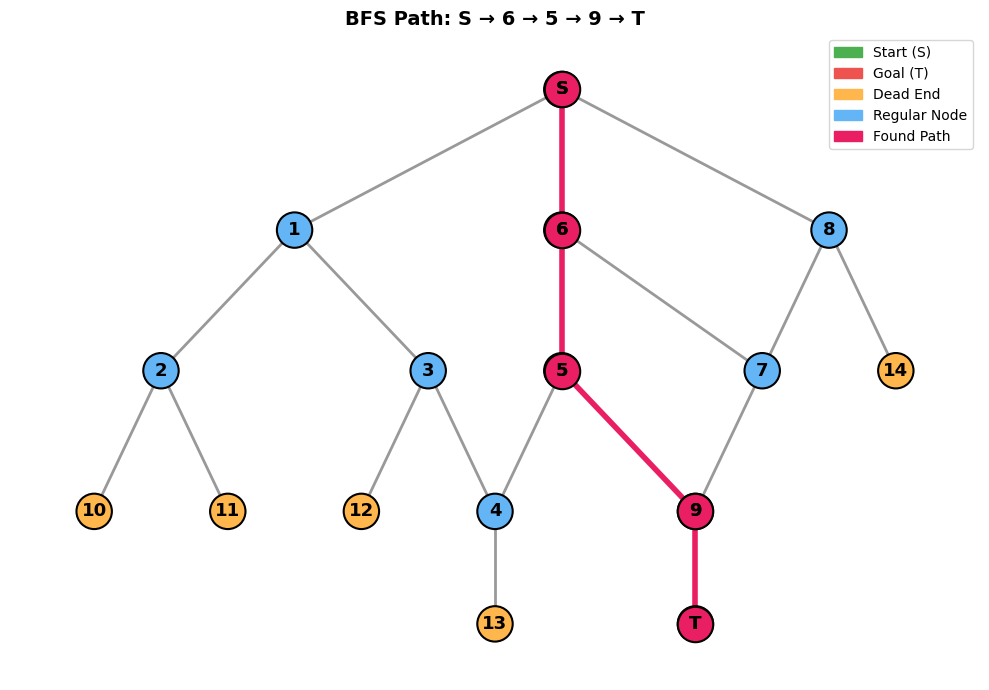

In [9]:
# Convert path to edges for highlighting
bfs_edges = list(zip(bfs_path[:-1], bfs_path[1:]))
draw_maze(maze, maze_pos, title=f'BFS Path: {" → ".join(bfs_path)}',
 highlight_edges=bfs_edges, highlight_nodes=bfs_path)

In [11]:
# NetworkX BFS shortest path
# TODO: get the shortest path using NetworkX's built-in BFS implementation
nx_bfs_path = nx.shortest_path(maze, source='S', target='T')

print(f"Our BFS path: {bfs_path}")
print(f"NetworkX BFS path: {list(nx_bfs_path)}")
print(f"Match: {bfs_path == list(nx_bfs_path)}")
# NetworkX BFS traversal order
nx_bfs_order = list(nx.bfs_tree(maze, 'S').nodes())
print(f"\nOur BFS order: {bfs_order}")
print(f"NetworkX BFS order: {nx_bfs_order}")

Our BFS path: ['S', '6', '5', '9', 'T']
NetworkX BFS path: ['S', '6', '5', '9', 'T']
Match: True

Our BFS order: ['S', '1', '6', '8', '2', '3', '5', '7', '14', '10', '11', '12', '4', '9', '13', 'T']
NetworkX BFS order: ['S', '1', '6', '8', '2', '3', '5', '7', '14', '10', '11', '12', '4', '9', '13', 'T']


In [21]:
def dfs_stack(graph, start, goal):
    """
    Depth-First Search using an explicit stack.

    Returns:
    traversal_order: List of nodes in the order they were visited
    path: Path from start to goal (None if not found)
    """
    visited = set()
    # LIFO stack: each entry is (node, path_to_node)
    stack = [(start, [start])]
    traversal_order = []

    while stack:
    # Pop from the TOP (LIFO)
    # TODO: use the proper Python List function to pop and get 'node' and 'path' from 'stack'
        node, path = stack.pop()

        if node in visited:
            continue

        # TODO: add 'node' to 'visited'
        visited.add(node)

        traversal_order.append(node)

        # Goal test
        if node == goal:
            return traversal_order, path

        # Push unvisited neighbours onto the stack
        # We push in REVERSE sorted order so that the alphabetically/numerically
        # first neighbour ends up on TOP of the stack (and gets explored first)
        for neighbor in sorted(graph.neighbors(node), reverse=True):
            if neighbor not in visited:
                stack.append((neighbor, path + [neighbor]))

    return traversal_order, None

In [22]:
def dfs_recursive(graph, start, goal, visited=None, path=None, traversal_order=None):
   """
   Depth-First Search using recursion.

   Returns:
   traversal_order: List of nodes in the order they were visited
   path: Path from start to goal (None if not found)
   """
   if visited is None:
      visited = set()
      path = [start]
      traversal_order = []

      # TODO: add 'start' to 'visited'
   visited.add(start)

   traversal_order.append(start)

   # Goal test
   if start == goal:
      return traversal_order, path

   # Explore neighbours in sorted order (left-to-right)
   for neighbor in sorted(graph.neighbors(start)):
      if neighbor not in visited:
         result_order, result_path = dfs_recursive(
               graph, neighbor, goal, visited, path + [neighbor], traversal_order
         )
         if result_path is not None:
            return result_order, result_path

   return traversal_order, None

In [23]:
dfs_s_order, dfs_s_path = dfs_stack(maze, 'S', 'T')
# TODO: run the recursive DFS and get the traversal order and path found
dfs_r_order, dfs_r_path = dfs_recursive(maze, 'S', 'T')
print("Stack-based DFS:")
print(f" Traversal order: {dfs_s_order}")
print(f" Path found: {' -> '.join(dfs_s_path)}")
print(f" Path length: {len(dfs_s_path) - 1} edges")
print(f"\nRecursive DFS:")
print(f" Traversal order: {dfs_r_order}")
print(f" Path found: {' -> '.join(dfs_r_path)}")
print(f" Path length: {len(dfs_r_path) - 1} edges")

Stack-based DFS:
 Traversal order: ['S', '1', '2', '10', '11', '3', '12', '4', '13', '5', '6', '7', '8', '14', '9', 'T']
 Path found: S -> 1 -> 3 -> 4 -> 5 -> 6 -> 7 -> 9 -> T
 Path length: 8 edges

Recursive DFS:
 Traversal order: ['S', '1', '2', '10', '11', '3', '12', '4', '13', '5', '6', '7', '8', '14', '9', 'T']
 Path found: S -> 1 -> 3 -> 4 -> 5 -> 6 -> 7 -> 9 -> T
 Path length: 8 edges


In [24]:
def trace_dfs(graph, start, goal):
    """Run stack-based DFS and print a detailed trace."""
    visited = set()
    stack = [(start, [start])]
    step = 0

    print(f"{'Step':>4} {'Visiting':>10} {'Stack (after expanding, top on RIGHT)':}")
    print("-" * 70)

    while stack:
    # TODO: pop and get 'node' and 'path' from 'stack' (see Cell 3.2)
        node, path = stack.pop()

        if node in visited:
            continue

        # TODO: add 'node' to 'visited'
        visited.add(node)

        step += 1

        if node == goal:
            print(f"{step:>4} {node:>10} ** GOAL FOUND **")
            print(f"\nPath: {' -> '.join(path)}")
            print(f"Path length: {len(path) - 1} edges")
            return path

        for neighbor in sorted(graph.neighbors(node), reverse=True):
            if neighbor not in visited:
                stack.append((neighbor, path + [neighbor]))

        stack_contents = [n for n, _ in stack]
        print(f"{step:>4} {node:>10} {stack_contents}")

    return None
dfs_result = trace_dfs(maze, 'S', 'T')

Step   Visiting Stack (after expanding, top on RIGHT)
----------------------------------------------------------------------
   1          S ['8', '6', '1']
   2          1 ['8', '6', '3', '2']
   3          2 ['8', '6', '3', '11', '10']
   4         10 ['8', '6', '3', '11']
   5         11 ['8', '6', '3']
   6          3 ['8', '6', '4', '12']
   7         12 ['8', '6', '4']
   8          4 ['8', '6', '5', '13']
   9         13 ['8', '6', '5']
  10          5 ['8', '6', '9', '6']
  11          6 ['8', '6', '9', '7']
  12          7 ['8', '6', '9', '9', '8']
  13          8 ['8', '6', '9', '9', '14']
  14         14 ['8', '6', '9', '9']
  15          9 ['8', '6', '9', 'T']
  16          T ** GOAL FOUND **

Path: S -> 1 -> 3 -> 4 -> 5 -> 6 -> 7 -> 9 -> T
Path length: 8 edges


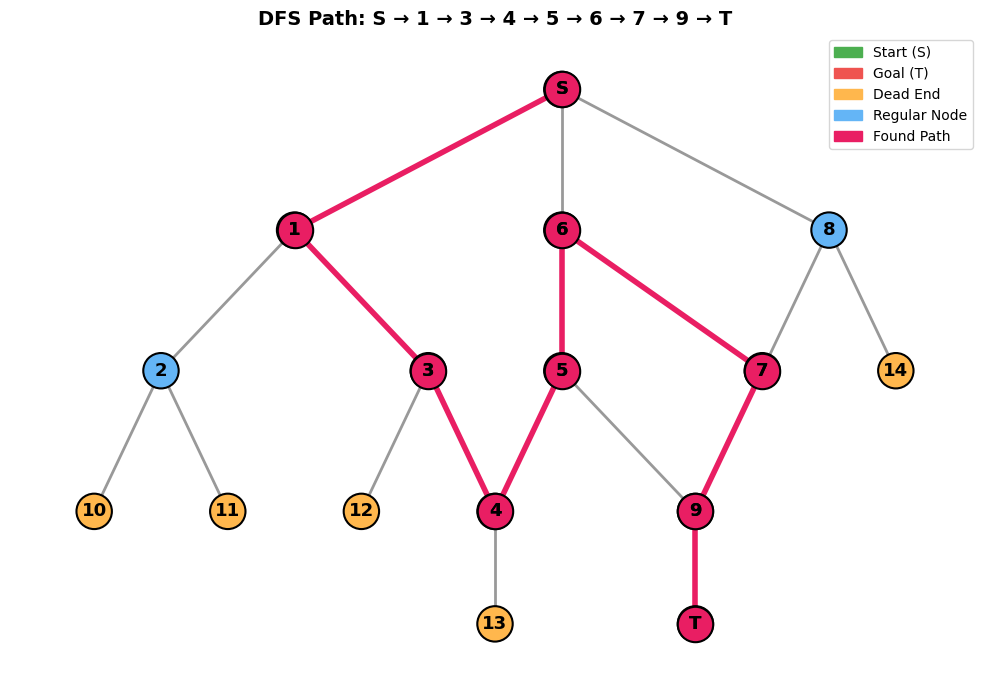

In [25]:
dfs_edges = list(zip(dfs_s_path[:-1], dfs_s_path[1:]))
draw_maze(maze, maze_pos, title=f'DFS Path: {" → ".join(dfs_s_path)}',
 highlight_edges=dfs_edges, highlight_nodes=dfs_s_path)

In [26]:
print("Comparison: BFS vs DFS on the Maze")
print("=" * 50)
print(f"{'':>20} {'BFS':>12} {'DFS (stack)':>12}")
print("-" * 50)
print(f"{'Path length':>20} {len(bfs_path)-1:>12} {len(dfs_s_path)-1:>12}")
print(f"{'Nodes visited':>20} {len(bfs_order):>12} {len(dfs_s_order):>12}")
print(f"{'Path':>20} {' -> '.join(bfs_path):>12}")
print(f"{'':>20} {' -> '.join(dfs_s_path):>12}")
print(f"\nBFS found the shorter path? {len(bfs_path) <= len(dfs_s_path)}")
print(f"DFS found the goal faster (fewer nodes visited)? {len(dfs_s_order) <= len(bfs_order)}")

Comparison: BFS vs DFS on the Maze
                              BFS  DFS (stack)
--------------------------------------------------
         Path length            4            8
       Nodes visited           16           16
                Path S -> 6 -> 5 -> 9 -> T
                     S -> 1 -> 3 -> 4 -> 5 -> 6 -> 7 -> 9 -> T

BFS found the shorter path? True
DFS found the goal faster (fewer nodes visited)? True


In [27]:
def depth_limited_dfs(graph, start, goal, limit):
    """
    Depth-Limited DFS using recursion.

    Parameters:
    graph: A NetworkX graph
    start: The starting node
    goal: The goal node
    In [ ]: In [ ]:
    limit: Maximum depth to search

    Returns:
    traversal_order: Nodes visited in order
    path: Path to goal, or None
    cutoff_occurred: True if the search was cut off by the depth limit
    """
    visited = set()
    traversal_order = []

    def _dldfs(node, path, depth):
        #TODO: add 'node' to 'visited'
        visited.add(node)

        traversal_order.append(node)

        if node == goal:
            return path, False # Found goal, no cutoff

        if depth >= limit:
            return None, True # Reached limit, cutoff occurred

        cutoff = False
        for neighbor in sorted(graph.neighbors(node)):
            if neighbor not in visited:
                result, child_cutoff = _dldfs(neighbor, path + [neighbor], depth + 1)
                if result is not None:
                    return result, False # Found goal
                if child_cutoff:
                    cutoff = True

        return None, cutoff

    path, cutoff = _dldfs(start, [start], 0)
    return traversal_order, path, cutoff

In [28]:
print(f"Depth-Limited DFS on the Maze (S -> T)")
print(f"{'Limit':>6} {'Found?':>7} {'Path Length':>12} {'Nodes Visited':>14} {'Cutoff?':>8}")
print("-" * 60)
for limit in range(1, 10):
 # TODO: run Depth-Limited DFS and get the resulting 'order', 'path', and 'cutoff'
   order, path, cutoff = depth_limited_dfs(maze, 'S', 'T', limit)

   found = path is not None
   plen = len(path) - 1 if found else '-'
   print(f"{limit:>6} {str(found):>7} {str(plen):>12} {len(order):>14} {str(cutoff):>8}")

Depth-Limited DFS on the Maze (S -> T)
 Limit  Found?  Path Length  Nodes Visited  Cutoff?
------------------------------------------------------------
     1   False            -              4     True
     2   False            -              9     True
     3   False            -             13     True
     4    True            4             16    False
     5   False            -             15     True
     6    True            6             14    False
     7   False            -             14     True
     8    True            8             16    False
     9    True            8             16    False


In [29]:
def iddfs(graph, start, goal, max_depth=50):
    """
    Iterative Deepening Depth-First Search.

    Repeatedly runs depth-limited DFS with increasing limits until the goal is found.

    Returns:
    traversal_order: Nodes visited in the final (successful) iteration
    In [ ]:
    O(b
    d)
    O(b ⋅ d)
    b/(b − 1) b = 2
    In [ ]:
    path: Path to goal, or None
    depth_found: The depth limit at which the goal was found
    total_expanded: Total nodes expanded across ALL iterations
    """
    total_expanded = 0

    for limit in range(max_depth + 1):
        # TODO: run Depth-Limited DFS and get the resulting 'order', 'path', and 'cutoff'
        order, path, cutoff = depth_limited_dfs(graph, start, goal, limit)

        total_expanded += len(order)

        if path is not None:
            return order, path, limit, total_expanded

        if not cutoff:
            # No cutoff and no goal — the entire graph has been searched
            break

    return [], None, -1, total_expanded

In [30]:
# TODO: run IDDFS and get the resulting order, path, depth, and total nodes
# 4.5 Run IDDFS
iddfs_order, iddfs_path, iddfs_depth, iddfs_total = iddfs(maze, 'S', 'T')
print(f"IDDFS Result:")
print(f" Goal found at depth limit: {iddfs_depth}")
print(f" Path: {' -> '.join(iddfs_path)}")
print(f" Path length: {len(iddfs_path) - 1} edges")
print(f" Nodes expanded in final iteration: {len(iddfs_order)}")
print(f" Total nodes expanded across all iterations: {iddfs_total}")
print(f"\nComparison:")
print(f" BFS path length: {len(bfs_path) - 1} (nodes expanded: {len(bfs_order)})")
print(f" IDDFS path length: {len(iddfs_path) - 1} (total expanded: {iddfs_total})")
print(f" Same optimal path? {len(iddfs_path) == len(bfs_path)}")

IDDFS Result:
 Goal found at depth limit: 4
 Path: S -> 6 -> 7 -> 9 -> T
 Path length: 4 edges
 Nodes expanded in final iteration: 16
 Total nodes expanded across all iterations: 43

Comparison:
 BFS path length: 4 (nodes expanded: 16)
 IDDFS path length: 4 (total expanded: 43)
 Same optimal path? True


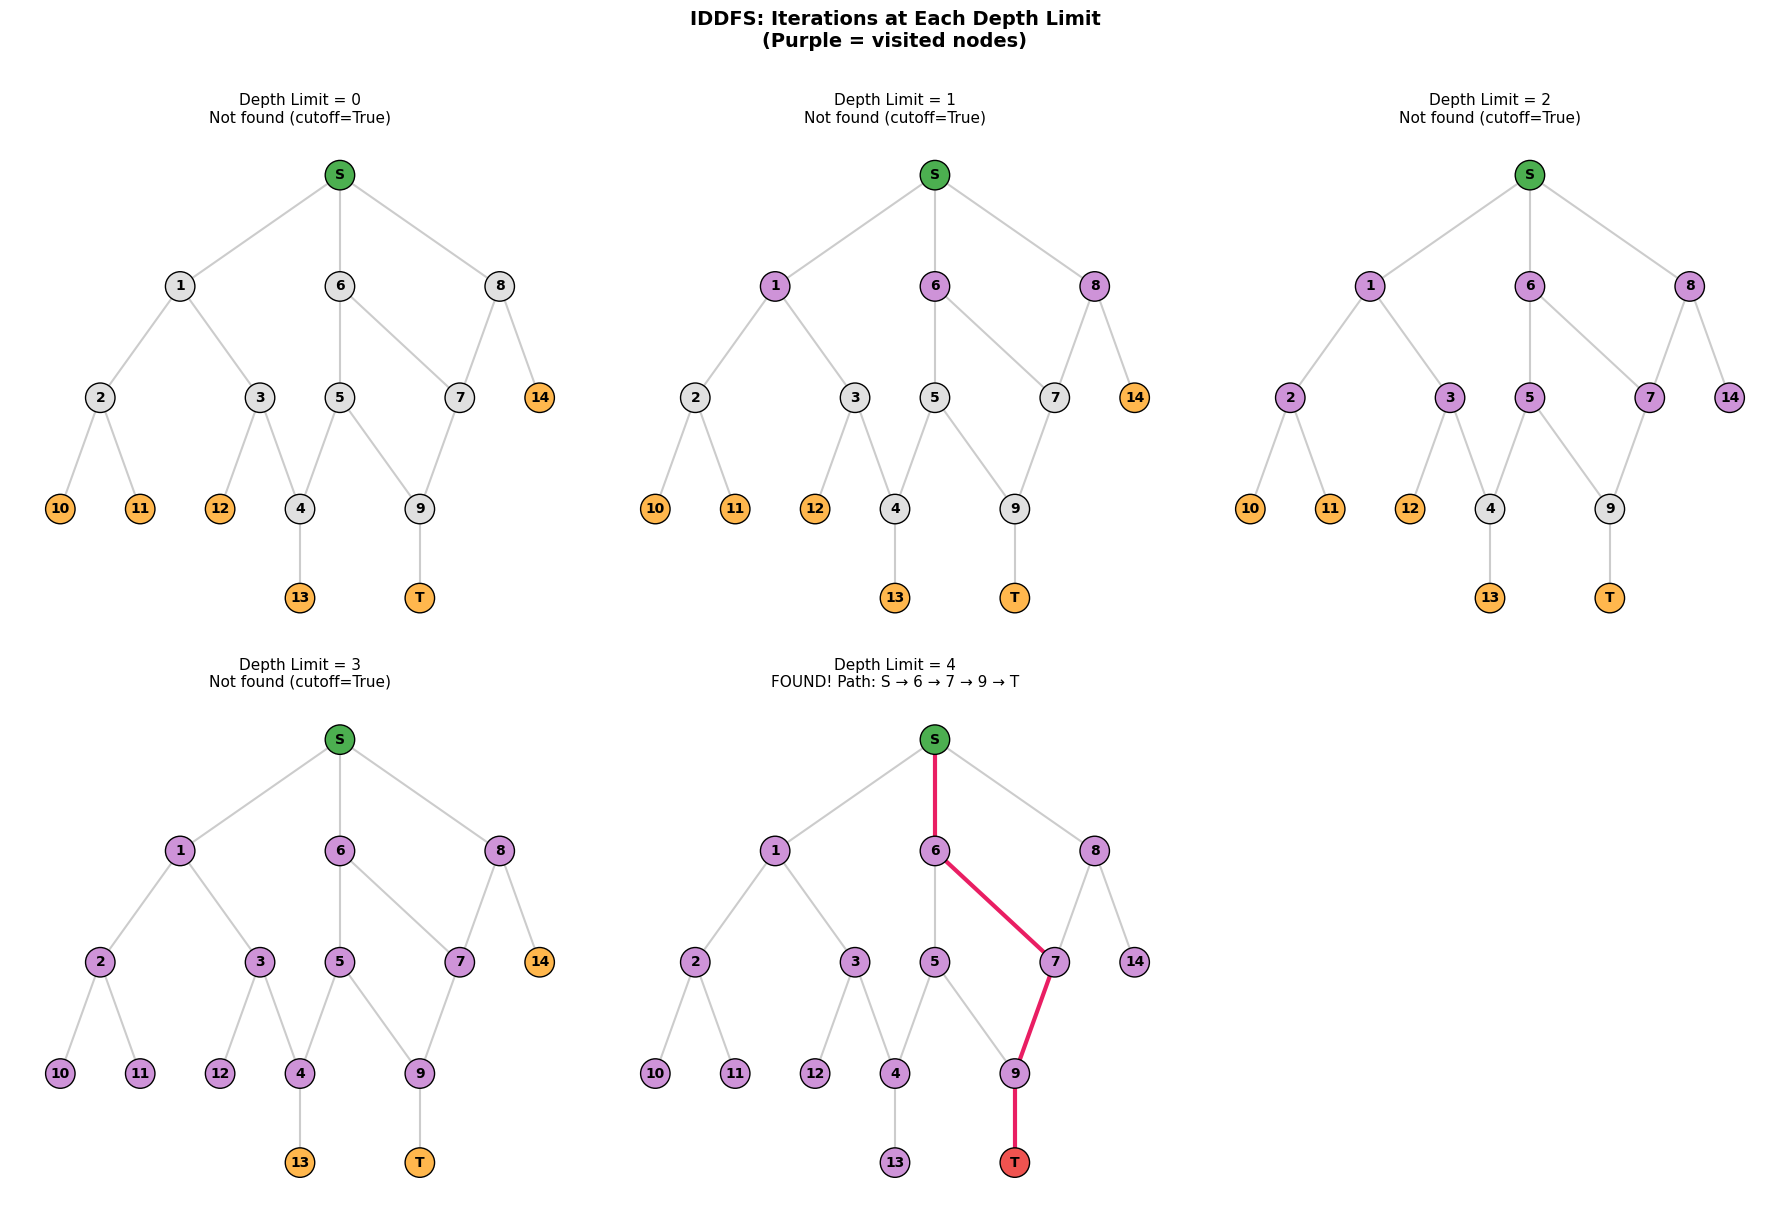

In [31]:
fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()
for i, limit in enumerate(range(iddfs_depth + 1)):
    ax = axes[i]
    # TODO: run Depth-Limited DFS and get the resulting 'order', 'path', and 'cutoff'
    order, path, cutoff = depth_limited_dfs(maze, 'S', 'T', limit)


    node_colors = []
    for n in maze.nodes():
        if n == 'S':
            node_colors.append('#4CAF50')
        elif n == 'T' and path is not None:
            node_colors.append('#EF5350')
        elif n in order:
            node_colors.append('#CE93D8') # Purple — visited
        elif maze.degree(n) == 1:
            node_colors.append('#FFB74D')
        else:
            node_colors.append('#E0E0E0') # Grey — not visited

    nx.draw(maze, maze_pos, ax=ax, with_labels=True,
        node_color=node_colors, node_size=450,
        font_size=10, font_weight='bold',
        edge_color='#CCCCCC', width=1.5,
        edgecolors='black', linewidths=1)

    if path:
        path_edges = list(zip(path[:-1], path[1:]))
        nx.draw_networkx_edges(maze, maze_pos, edgelist=path_edges,
                               edge_color='#E91E63', width=3, ax=ax)

    status = f"FOUND! Path: {' → '.join(path)}" if path else f"Not found (cutoff={cutoff})"
    ax.set_title(f'Depth Limit = {limit}\n{status}', fontsize=11)
# Hide unused subplot
for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)
plt.suptitle('IDDFS: Iterations at Each Depth Limit\n(Purple = visited nodes)',
            fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

In [32]:
# Comprehensive comparison
print("Algorithm Comparison on the Maze (S -> T)")
print("=" * 75)
print(f"{'Algorithm':<25} {'Path Length':>12} {'Nodes Visited':>14} {'Optimal?':>10} {'Complete?':>10}")
print("-" * 75)
algorithms = [
 ("BFS", bfs_path, bfs_order),
 ("DFS (stack)", dfs_s_path, dfs_s_order),
 # TODO: include recursive DFS results
("DFS (recursive)", dfs_r_path, dfs_r_order),
 # TODO: include IDDFS results
("IDDFS", iddfs_path, iddfs_order),
]
for name, path, order in algorithms:
    plen = len(path) - 1 if path else '-'
    optimal = "Yes" if path and len(path) == len(bfs_path) else "No"
    print(f"{name:<25} {str(plen):>12} {len(order):>14} {optimal:>10} {'Yes':>10}")
print(f"\nIDDFS total expanded across all iterations: {iddfs_total}")

Algorithm Comparison on the Maze (S -> T)
Algorithm                  Path Length  Nodes Visited   Optimal?  Complete?
---------------------------------------------------------------------------
BFS                                  4             16        Yes        Yes
DFS (stack)                          8             16         No        Yes
DFS (recursive)                      8             16         No        Yes
IDDFS                                4             16        Yes        Yes

IDDFS total expanded across all iterations: 43
